In [3]:
import pandas as pd

data = {
    "loan_id": ["L001", "L002", "L003", "L004", "L005", "L006"],
    "student_id": ["S101", "S102", "S103", "S104", "S105", "S106"],
    "book_id": ["B101", "B102", "B103", "B104", "B105", "B106"],
    "category": [
        "Programming", "Mathematics", "Programming",
        "Data Science", "Electronics", "Programming"
    ],
    "loan_date": [
        "2026-01-05", "2026-01-08", "2026-01-12",
        "2026-02-02", "2026-02-10", "2026-02-14"
    ],
    "due_date": [
        "2026-01-19", "2026-01-22", "2026-01-26",
        "2026-02-16", "2026-02-24", "2026-02-28"
    ],
    "return_date": [
        "2026-01-15", "2026-01-25", "2026-01-24",
        "2026-02-15", None, "2026-03-02"
    ]
}

df = pd.DataFrame(data)

for col in ["loan_date", "due_date", "return_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

df.to_csv("loans.csv", index=False)

print("Dataset created successfully!")
display(df)

Dataset created successfully!


,loan_id,student_id,book_id,category,loan_date,due_date,return_date
0,L001,S101,B101,Programming,2026-01-05,2026-01-19,2026-01-15
1,L002,S102,B102,Mathematics,2026-01-08,2026-01-22,2026-01-25
2,L003,S103,B103,Programming,2026-01-12,2026-01-26,2026-01-24
3,L004,S104,B104,Data Science,2026-02-02,2026-02-16,2026-02-15
4,L005,S105,B105,Electronics,2026-02-10,2026-02-24,NaT
5,L006,S106,B106,Programming,2026-02-14,2026-02-28,2026-03-02


LIBRARY CIRCULATION AND DEMAND DASHBOARD

Total records: 6
Unique loan IDs: 6
Records with issues: 0
Clean records analysed: 6

--- CATEGORY FREQUENCY ---
    category  number of loans
 Programming                3
 Mathematics                1
Data Science                1
 Electronics                1

--- CATEGORY SUMMARY ---
    category  total_loans  unique_books  unique_students
 Programming            3             3                3
Data Science            1             1                1
 Electronics            1             1                1
 Mathematics            1             1                1

--- MONTHLY SUMMARY ---
  month  total_loans
2026-01            3
2026-02            3

--- OVERDUE LOANS ---
Loan ID: L002 | Book: B102 | Category: Mathematics | Returned late
Loan ID: L005 | Book: B105 | Category: Electronics | Not yet returned
Loan ID: L006 | Book: B106 | Category: Programming | Returned late

--- DATA QUALITY REPORT ---
No data quality issues.

--- LOAN DURATI

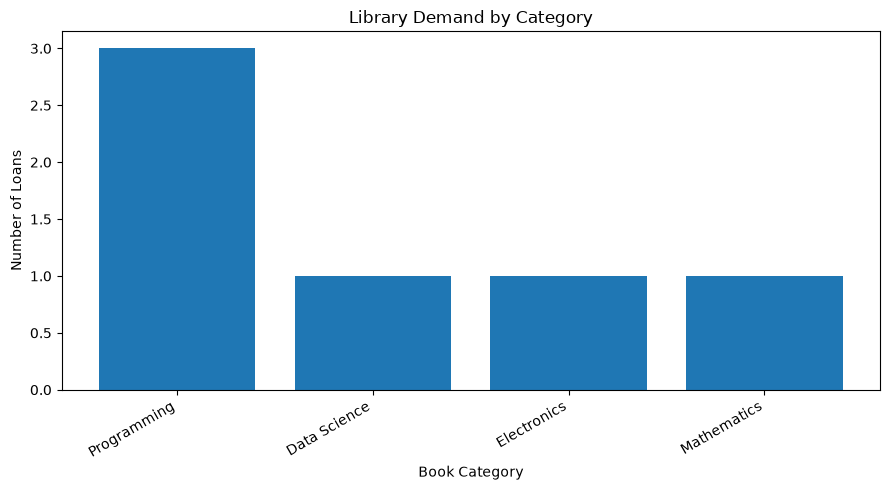

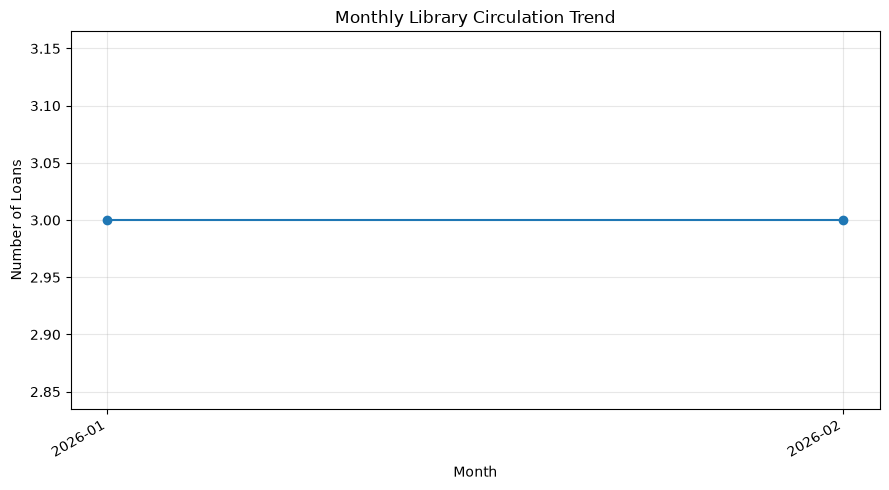


--- FINAL EVALUATION ---
Highest-demand category: Programming
Number of loans: 3
Average loan duration: 54.5
Reports saved in: output
Dashboard completed successfully.

--- JSON SUMMARY ---
{
    "report_date": "2026-10-27",
    "total_records": 6,
    "unique_loan_ids": 6,
    "records_with_issues": 0,
    "clean_records_analysed": 6,
    "overdue_loans": 3,
    "highest_demand_category": "Programming",
    "highest_category_loan_count": 3,
    "average_loan_duration_days": 54.5
}


In [2]:
# LIBRARY CIRCULATION AND DEMAND DASHBOARD
# Second-Year Python Project

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datetime import date

%matplotlib inline

# ------------------------------------------
# 1. PROJECT SETTINGS
# ------------------------------------------

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TODAY = pd.Timestamp(date.today()).normalize()
df= pd.read_csv("loans.csv")
# Ensure dates are in datetime format
for col in ["loan_date", "due_date", "return_date"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Remove extra spaces from text columns
for col in ["loan_id", "student_id", "book_id", "category"]:
    df[col] = df[col].astype("string").str.strip()

# Convert empty strings into missing values
df = df.replace(r"^\s*$", pd.NA, regex=True)

# ------------------------------------------
# 2. LOAN RECORD CLASS
# ------------------------------------------

class LoanRecord:

    def __init__(self, loan_id, student_id, book_id,
                 category, loan_date, due_date, return_date):

        self.loan_id = loan_id
        self.student_id = student_id
        self.book_id = book_id
        self.category = category
        self.loan_date = loan_date
        self.due_date = due_date
        self.return_date = return_date

    def is_overdue(self, today=TODAY):

        if pd.isna(self.due_date):
            return False

        if pd.notna(self.return_date):
            return self.return_date.normalize() > self.due_date.normalize()

        return today > self.due_date.normalize()

    def loan_duration(self, today=TODAY):

        if pd.isna(self.loan_date):
            return np.nan

        end_date = (
            self.return_date
            if pd.notna(self.return_date)
            else today
        )

        days = (end_date.normalize() -
                self.loan_date.normalize()).days

        return days if days >= 0 else np.nan


# ------------------------------------------
# 3. FREQUENCY COUNT FUNCTION
# ------------------------------------------

def frequency_count(data, column):
    return data[column].value_counts()


# ------------------------------------------
# 4. DATA QUALITY CHECK
# ------------------------------------------

def check_data_quality(data):

    report = data.copy()

    mandatory = [
        "loan_id", "student_id", "book_id",
        "category", "loan_date", "due_date"
    ]

    report["missing_fields"] = report.apply(
        lambda row: ", ".join(
            col for col in mandatory if pd.isna(row[col])
        ),
        axis=1
    )

    report["duplicate_loan_id"] = (
        report["loan_id"].notna()
        & report["loan_id"].duplicated(keep=False)
    )

    report["invalid_dates"] = (
        (
            report["loan_date"].notna()
            & report["due_date"].notna()
            & (report["due_date"] < report["loan_date"])
        )
        |
        (
            report["return_date"].notna()
            & report["loan_date"].notna()
            & (report["return_date"] < report["loan_date"])
        )
    )

    def identify_issues(row):

        issues = []

        if row["missing_fields"]:
            issues.append("Missing fields: " + row["missing_fields"])

        if row["duplicate_loan_id"]:
            issues.append("Duplicate loan ID")

        if row["invalid_dates"]:
            issues.append("Invalid dates")

        return "; ".join(issues) if issues else "No issue"

    report["data_issue"] = report.apply(
        identify_issues, axis=1
    )

    return report


# ------------------------------------------
# 5. CREATE LOAN OBJECTS
# ------------------------------------------

def create_loan_objects(data):

    loans = []

    for _, row in data.iterrows():

        loans.append(
            LoanRecord(
                row["loan_id"],
                row["student_id"],
                row["book_id"],
                row["category"],
                row["loan_date"],
                row["due_date"],
                row["return_date"]
            )
        )

    return loans


# ------------------------------------------
# 6. OVERDUE CHECK
# ------------------------------------------

def overdue_report(loans):

    return [
        loan for loan in loans
        if loan.is_overdue()
    ]


# ------------------------------------------
# 7. NUMPY LOAN DURATION
# ------------------------------------------

def calculate_durations(data):

    end_dates = data["return_date"].fillna(TODAY)

    durations = (
        end_dates - data["loan_date"]
    ).dt.days

    durations = durations.where(
        data["loan_date"].notna(), np.nan
    )

    durations = durations.where(
        durations >= 0, np.nan
    )

    return durations.to_numpy(dtype=float)


# ------------------------------------------
# 8. CATEGORY AND MONTHLY SUMMARIES
# ------------------------------------------

def create_summaries(data):

    category_summary = (
        data.groupby("category")
        .agg(
            total_loans=("loan_id", "count"),
            unique_books=("book_id", "nunique"),
            unique_students=("student_id", "nunique")
        )
        .sort_values("total_loans", ascending=False)
        .reset_index()
    )

    monthly_data = data.dropna(
        subset=["loan_date"]
    ).copy()

    monthly_data["month"] = (
        monthly_data["loan_date"]
        .dt.to_period("M")
        .astype(str)
    )

    monthly_summary = (
        monthly_data.groupby("month")
        .size()
        .reset_index(name="total_loans")
        .sort_values("month")
    )

    return category_summary, monthly_summary


# ------------------------------------------
# 9. CREATE CHARTS
# ------------------------------------------

def draw_charts(category_summary, monthly_summary):

    # Category bar chart
    if not category_summary.empty:

        plt.figure(figsize=(9, 5))

        plt.bar(
            category_summary["category"],
            category_summary["total_loans"]
        )

        plt.title("Library Demand by Category")
        plt.xlabel("Book Category")
        plt.ylabel("Number of Loans")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            os.path.join(OUTPUT_DIR, "category_demand.png")
        )

        plt.show()
        plt.close()

    # Monthly trend chart
    if not monthly_summary.empty:

        plt.figure(figsize=(9, 5))

        plt.plot(
            monthly_summary["month"],
            monthly_summary["total_loans"],
            marker="o"
        )

        plt.title("Monthly Library Circulation Trend")
        plt.xlabel("Month")
        plt.ylabel("Number of Loans")
        plt.xticks(rotation=30, ha="right")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            os.path.join(OUTPUT_DIR, "monthly_trend.png")
        )

        plt.show()
        plt.close()


# ------------------------------------------
# 10. EXPORT REPORTS
# ------------------------------------------

def export_reports(category_summary, monthly_summary,
                   quality_report, summary):

    category_summary.to_csv(
        os.path.join(OUTPUT_DIR, "category_summary.csv"),
        index=False
    )

    monthly_summary.to_csv(
        os.path.join(OUTPUT_DIR, "monthly_summary.csv"),
        index=False
    )

    quality_report.to_csv(
        os.path.join(OUTPUT_DIR, "data_quality_report.csv"),
        index=False
    )

    with open(
        os.path.join(OUTPUT_DIR, "library_summary.json"),
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            summary, file, indent=4, allow_nan=False
        )


# ------------------------------------------
# 11. RUN THE DASHBOARD
# ------------------------------------------

quality_report = check_data_quality(df)

# Only clean records are used for category/month summaries
clean_mask = quality_report["data_issue"].eq("No issue")
clean_df = df.loc[clean_mask].copy()

# Create objects and find overdue loans
loans = create_loan_objects(df)
overdue_loans = overdue_report(loans)

# Calculate duration
df["loan_duration_days"] = calculate_durations(df)

# Generate summaries
category_summary, monthly_summary = create_summaries(
    clean_df
)

# ------------------------------------------
# 12. DISPLAY RESULTS
# ------------------------------------------

print("=" * 50)
print("LIBRARY CIRCULATION AND DEMAND DASHBOARD")
print("=" * 50)

print("\nTotal records:", len(df))
print("Unique loan IDs:", df["loan_id"].nunique())
print("Records with issues:", int((~clean_mask).sum()))
print("Clean records analysed:", len(clean_df))

print("\n--- CATEGORY FREQUENCY ---")

if clean_df.empty:
    print("No clean records available.")
else:
    freq_df = clean_df['category'].value_counts().reset_index(name='number of loans')
    print(freq_df.to_string(index=False))

print("\n--- CATEGORY SUMMARY ---")
print(category_summary.to_string(index=False))

print("\n--- MONTHLY SUMMARY ---")
print(monthly_summary.to_string(index=False))

print("\n--- OVERDUE LOANS ---")

if overdue_loans:

    for loan in overdue_loans:

        status = (
            "Returned late"
            if pd.notna(loan.return_date)
            else "Not yet returned"
        )

        print(
            f"Loan ID: {loan.loan_id} | "
            f"Book: {loan.book_id} | "
            f"Category: {loan.category} | {status}"
        )

else:
    print("No overdue loans.")

print("\n--- DATA QUALITY REPORT ---")

issues = quality_report[
    quality_report["data_issue"] != "No issue"
]

if issues.empty:
    print("No data quality issues.")
else:
    print(
        issues[
            ["loan_id", "data_issue"]
        ].to_string(index=False)
    )

print("\n--- LOAN DURATIONS ---")

print(
    df[
        ["loan_id", "loan_duration_days"]
    ].to_string(index=False)
)

# ------------------------------------------
# 13. VISUALISATION
# ------------------------------------------

draw_charts(category_summary, monthly_summary)

# ------------------------------------------
# 14. FINAL EVALUATION AND JSON EXPORT
# ------------------------------------------

if not category_summary.empty:

    top = category_summary.iloc[0]

    top_category = str(top["category"])
    top_count = int(top["total_loans"])

else:

    top_category = "None"
    top_count = 0

duration_values = df.loc[
    clean_mask, "loan_duration_days"
].to_numpy(dtype=float)

valid_values = duration_values[
    ~np.isnan(duration_values)
]

average_duration = (
    round(float(np.mean(valid_values)), 2)
    if len(valid_values) else None
)

summary = {
    "report_date": str(TODAY.date()),
    "total_records": int(len(df)),
    "unique_loan_ids": int(df["loan_id"].nunique()),
    "records_with_issues": int((~clean_mask).sum()),
    "clean_records_analysed": int(len(clean_df)),
    "overdue_loans": int(len(overdue_loans)),
    "highest_demand_category": top_category,
    "highest_category_loan_count": top_count,
    "average_loan_duration_days": average_duration
}

export_reports(
    category_summary,
    monthly_summary,
    quality_report,
    summary
)

print("\n--- FINAL EVALUATION ---")
print("Highest-demand category:", top_category)
print("Number of loans:", top_count)
print("Average loan duration:", average_duration)
print("Reports saved in:", OUTPUT_DIR)
print("Dashboard completed successfully.")

# Display JSON summary
print("\n--- JSON SUMMARY ---")
print(json.dumps(summary, indent=4))